# DS_Day01_34 - E-Commerce: Who Are Our Customers?

## 1. Project Objective

**Industry:** Retail and E-Commerce

This project analyses the UCI Online Retail dataset to build a
behaviour-based customer segmentation and translate it into marketing actions.

**Five customer-level features engineered from raw transactions:**

| Feature | Description |
|---|---|
| Customer_ID | Unique customer identifier |
| Purchase_Frequency | Number of distinct invoices per customer |
| Recency | Days since last purchase (reference: 2011-12-10) |
| Spending | Total revenue generated per customer |
| Product_Diversity | Number of distinct products purchased |

**Discount_Usage — not available in this dataset.**
The UCI Online Retail file contains no discount, coupon, original-price,
or markdown field. This feature cannot be calculated without fabricating data
and is excluded. This limitation is documented fully in Section 19.

**Specified ML algorithm:** KNN (sklearn NearestNeighbors, unsupervised)

## 2. Dataset Overview

In [1]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

df_raw = pd.read_excel('dataset/Online Retail.xlsx')
print("Shape          :", df_raw.shape)
print("Columns        :", df_raw.columns.tolist())
print("Date range     :", df_raw['InvoiceDate'].min(), "to", df_raw['InvoiceDate'].max())
print("Unique customers (incl NaN):", df_raw['CustomerID'].nunique())
print("Unique invoices:", df_raw['InvoiceNo'].nunique())
print("Unique products:", df_raw['StockCode'].nunique())
print("Countries      :", df_raw['Country'].nunique())
print()
print(df_raw.dtypes)
df_raw.head()

Shape          : (541909, 8)
Columns        : ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
Date range     : 2010-12-01 08:26:00 to 2011-12-09 12:50:00
Unique customers (incl NaN): 4372
Unique invoices: 25900
Unique products: 4070
Countries      : 38

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 3. Data Cleaning

Cleaning steps applied in order:

| Step | Condition | Reason |
|---|---|---|
| 1 | Exact duplicate rows | Same invoice, item, date, customer — data entry errors |
| 2 | Missing CustomerID | Cannot attribute to any customer |
| 3 | Cancelled invoices (InvoiceNo starts with 'C') | Returns/refunds, not purchases |
| 4 | UnitPrice <= 0 | Free samples or data errors — no revenue |

Legitimate extreme purchases (large Quantity or high UnitPrice with valid
CustomerID and positive values) are **retained**.

In [2]:
df = df_raw.copy()

n_dupes = df.duplicated().sum()
df = df.drop_duplicates()
print("1. Duplicate rows removed         :", n_dupes)

n_no_cust = df['CustomerID'].isna().sum()
df = df[df['CustomerID'].notna()]
print("2. Rows missing CustomerID removed :", n_no_cust)

cancelled = df['InvoiceNo'].astype(str).str.startswith('C')
n_cancelled = cancelled.sum()
df = df[~cancelled]
print("3. Cancelled transaction rows      :", n_cancelled)

n_bad_price = (df['UnitPrice'] <= 0).sum()
df = df[df['UnitPrice'] > 0]
print("4. Rows with UnitPrice <= 0        :", n_bad_price)

print()
print("Clean dataset shape:", df.shape)
print("Unique customers   :", df['CustomerID'].nunique())

1. Duplicate rows removed         : 5268
2. Rows missing CustomerID removed : 135037


3. Cancelled transaction rows      : 8872
4. Rows with UnitPrice <= 0        : 40

Clean dataset shape: (392692, 8)
Unique customers   : 4338


## 4. Data Validation

In [3]:
print("=== Post-cleaning validation ===")
print(df.isnull().sum())
print()
print("Negative Quantity rows :", (df['Quantity'] < 0).sum())
print("Zero/negative UnitPrice:", (df['UnitPrice'] <= 0).sum())
print("Remaining duplicates   :", df.duplicated().sum())
print()
df[['Quantity', 'UnitPrice']].describe().round(2)

=== Post-cleaning validation ===
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

Negative Quantity rows : 0
Zero/negative UnitPrice: 0


Remaining duplicates   : 0



,Quantity,UnitPrice
count,392692.00,392692.00
mean,13.12,3.13
std,180.49,22.24
min,1.00,0.00
25%,2.00,1.25
50%,6.00,1.95
75%,12.00,3.75
max,80995.00,8142.75


In [4]:
print("Top 10 largest Quantity transactions (retained as legitimate bulk orders):")
print(df.nlargest(10, 'Quantity')[
    ['InvoiceNo','StockCode','Description','Quantity','UnitPrice','CustomerID']
].to_string())

Top 10 largest Quantity transactions (retained as legitimate bulk orders):
       InvoiceNo StockCode                          Description  Quantity  UnitPrice  CustomerID
540421    581483     23843          PAPER CRAFT , LITTLE BIRDIE     80995       2.08     16446.0
61619     541431     23166       MEDIUM CERAMIC TOP STORAGE JAR     74215       1.04     12346.0
421632    573008     84077    WORLD WAR 2 GLIDERS ASSTD DESIGNS      4800       0.21     12901.0
206121    554868     22197                 SMALL POPCORN HOLDER      4300       0.72     13135.0
97432     544612     22053                EMPIRE DESIGN ROSETTE      3906       0.82     18087.0
270885    560599     18007  ESSENTIAL BALM 3.5g TIN IN ENVELOPE      3186       0.06     14609.0
52711     540815     21108   FAIRY CAKE FLANNEL ASSORTED COLOUR      3114       2.10     15749.0
160546    550461     21108   FAIRY CAKE FLANNEL ASSORTED COLOUR      3114       2.10     15749.0
433788    573995     16014          SMALL CHINESE ST

In [5]:
print("Top 10 largest UnitPrice transactions (retained as legitimate high-value orders):")
print(df.nlargest(10, 'UnitPrice')[
    ['InvoiceNo','StockCode','Description','Quantity','UnitPrice','CustomerID']
].to_string())
print()
print("All extreme records have valid CustomerIDs and positive prices.")
print("No further removal applied.")

Top 10 largest UnitPrice transactions (retained as legitimate high-value orders):
       InvoiceNo StockCode Description  Quantity  UnitPrice  CustomerID
173382    551697      POST     POSTAGE         1    8142.75     16029.0
422351    573077         M      Manual         1    4161.06     12536.0
422376    573080         M      Manual         1    4161.06     12536.0
406406    571751         M      Manual         1    3949.32     12744.0
374542    569382         M      Manual         1    3155.95     15502.0
297438    562946         M      Manual         1    2500.00     15581.0
144826    548813         M      Manual         1    2382.92     12744.0
406407    571751         M      Manual         1    2118.74     12744.0
144829    548820         M      Manual         1    2053.07     12744.0
343000    566927         M      Manual         1    2033.10     17846.0

All extreme records have valid CustomerIDs and positive prices.
No further removal applied.


## 5. Customer-Level Feature Engineering

Reference date: **2011-12-10** (one day after the last transaction 2011-12-09).

| Feature | Formula |
|---|---|
| Purchase_Frequency | count(distinct InvoiceNo) per customer |
| Recency | (2011-12-10 - max(InvoiceDate)).days per customer |
| Spending | sum(Quantity x UnitPrice) per customer |
| Product_Diversity | count(distinct StockCode) per customer |

In [6]:
reference_date = pd.Timestamp('2011-12-10')
df['Revenue'] = df['Quantity'] * df['UnitPrice']

customers = df.groupby('CustomerID').agg(
    Purchase_Frequency=('InvoiceNo',   lambda x: x.nunique()),
    Recency           =('InvoiceDate', lambda x: (reference_date - x.max()).days),
    Spending          =('Revenue',     'sum'),
    Product_Diversity =('StockCode',   lambda x: x.nunique())
).reset_index()

customers.rename(columns={'CustomerID': 'Customer_ID'}, inplace=True)
print("Customer-level dataframe shape:", customers.shape)
customers.head(10)

Customer-level dataframe shape: (4338, 5)


,Customer_ID,Purchase_Frequency,Recency,Spending,Product_Diversity
0,12346.0,1,325,77183.60,1
1,12347.0,7,2,4310.00,103
2,12348.0,4,75,1797.24,22
3,12349.0,1,18,1757.55,73
4,12350.0,1,310,334.40,17
5,12352.0,8,36,2506.04,59
6,12353.0,1,204,89.00,4
7,12354.0,1,232,1079.40,58
8,12355.0,1,214,459.40,13
9,12356.0,3,22,2811.43,53


## 6. Descriptive Statistics

In [7]:
stats = customers[['Purchase_Frequency','Recency','Spending','Product_Diversity']].agg(
    ['count','mean','median','std','min',
     lambda x: x.quantile(0.25),
     lambda x: x.quantile(0.75),
     'max']
).T
stats.columns = ['count','mean','median','std','min','Q1','Q3','max']
print(stats.round(2).to_string())

                     count     mean  median      std   min      Q1       Q3        max
Purchase_Frequency  4338.0     4.27    2.00     7.70  1.00    1.00     5.00     209.00
Recency             4338.0    92.06   50.00   100.01  0.00   17.00   141.75     373.00
Spending            4338.0  2048.69  668.57  8985.23  3.75  306.48  1660.60  280206.02
Product_Diversity   4338.0    61.50   35.00    85.37  1.00   16.00    77.00    1787.00


In [8]:
from scipy.stats import skew

print("Skewness analysis:")
for col in ['Purchase_Frequency','Recency','Spending','Product_Diversity']:
    sk = skew(customers[col])
    if sk > 1:
        label = "right-skewed — a small number of customers have very high values"
    elif sk < -1:
        label = "left-skewed"
    else:
        label = "approximately symmetric"
    print("  {:25s}: {:6.2f}  -> {}".format(col, sk, label))
print()
print("All four features are right-skewed, which is typical for retail customer data.")
print("A small number of high-value customers pull the mean above the median.")

Skewness analysis:
  Purchase_Frequency       :  12.06  -> right-skewed — a small number of customers have very high values
  Recency                  :   1.25  -> right-skewed — a small number of customers have very high values
  Spending                 :  19.33  -> right-skewed — a small number of customers have very high values
  Product_Diversity        :   6.92  -> right-skewed — a small number of customers have very high values

All four features are right-skewed, which is typical for retail customer data.
A small number of high-value customers pull the mean above the median.


### EDA — Correlation Heatmap (exploratory, not one of the 4 required visualizations)

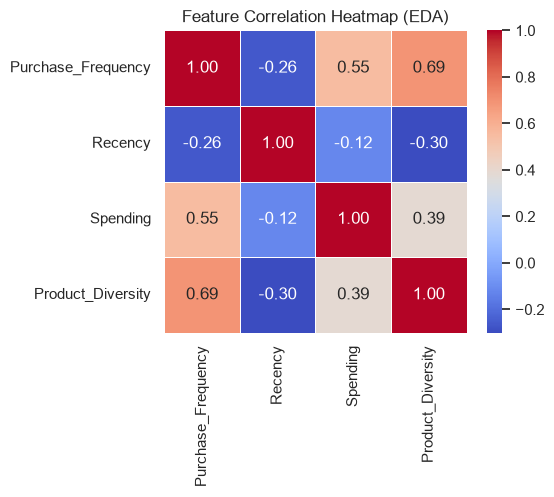

Saved: eda_correlation_heatmap.png


In [9]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
sns.set_theme(style='whitegrid', palette='muted')

corr = customers[['Purchase_Frequency','Recency','Spending','Product_Diversity']].corr()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            square=True, linewidths=0.5, ax=ax)
ax.set_title('Feature Correlation Heatmap (EDA)')
plt.tight_layout()
plt.savefig('eda_correlation_heatmap.png', dpi=150)
plt.show()
print("Saved: eda_correlation_heatmap.png")

## 7. RFM Calculation

- **R** = Recency — days since last purchase (lower = more recent = better)
- **F** = Purchase_Frequency — number of invoices (higher = better)
- **M** = Spending — total revenue (higher = better)

In [10]:
customers['R'] = customers['Recency']
customers['F'] = customers['Purchase_Frequency']
customers['M'] = customers['Spending']

print("RFM raw value summary:")
customers[['R','F','M']].describe().round(2)

RFM raw value summary:


,R,F,M
count,4338.00,4338.00,4338.00
mean,92.06,4.27,2048.69
std,100.01,7.70,8985.23
min,0.00,1.00,3.75
25%,17.00,1.00,306.48
50%,50.00,2.00,668.57
75%,141.75,5.00,1660.60
max,373.00,209.00,280206.02


## 8. RFM Scoring

Quintile-based 1-5 scores:
- **R_Score**: reversed — lower Recency days = score 5 (most recent = best)
- **F_Score**: higher frequency = score 5
- **M_Score**: higher spending = score 5

`rank(method='first')` breaks ties before qcut.

**RFM_Score = R_Score + F_Score + M_Score** (range: 3 to 15)

In [11]:
customers['R_Score'] = pd.qcut(
    customers['R'], q=5, labels=[5,4,3,2,1]).astype(int)

customers['F_Score'] = pd.qcut(
    customers['F'].rank(method='first'), q=5, labels=[1,2,3,4,5]).astype(int)

customers['M_Score'] = pd.qcut(
    customers['M'].rank(method='first'), q=5, labels=[1,2,3,4,5]).astype(int)

customers['RFM_Score'] = customers['R_Score'] + customers['F_Score'] + customers['M_Score']

print("RFM Score distribution:")
print(customers['RFM_Score'].describe().round(2))
print()
print("Score value counts (3=lowest, 15=highest):")
print(customers['RFM_Score'].value_counts().sort_index())

RFM Score distribution:
count    4338.00
mean        9.01
std         3.59
min         3.00
25%         6.00
50%         9.00
75%        12.00
max        15.00
Name: RFM_Score, dtype: float64

Score value counts (3=lowest, 15=highest):
RFM_Score
3     182
4     363
5     338
6     427
7     382
8     373
9     333
10    344
11    349
12    316
13    287
14    297
15    347
Name: count, dtype: int64


## 9. Customer Segmentation

Segments defined from the **actual RFM_Score distribution** using quartiles.
No arbitrary thresholds invented.

- **High Value**: RFM_Score >= Q75
- **Mid Value**: Q25 <= RFM_Score < Q75
- **Low Value**: RFM_Score < Q25

In [12]:
q25 = customers['RFM_Score'].quantile(0.25)
q75 = customers['RFM_Score'].quantile(0.75)
print("RFM_Score Q25 (Low/Mid boundary) :", q25)
print("RFM_Score Q75 (Mid/High boundary):", q75)

def assign_segment(score):
    if score >= q75:
        return 'High Value'
    elif score < q25:
        return 'Low Value'
    return 'Mid Value'

customers['Segment'] = customers['RFM_Score'].apply(assign_segment)

print()
print("Segment counts:")
print(customers['Segment'].value_counts())
print()
print("Segment mean RFM features:")
print(customers.groupby('Segment')[['R','F','M','Product_Diversity']].mean().round(2).to_string())

RFM_Score Q25 (Low/Mid boundary) : 6.0
RFM_Score Q75 (Mid/High boundary): 12.0

Segment counts:
Segment
Mid Value     2208
High Value    1247
Low Value      883
Name: count, dtype: int64

Segment mean RFM features:
                 R     F        M  Product_Diversity
Segment                                             
High Value   18.55  9.99  5452.72             126.85
Low Value   223.91  1.05   228.66              16.42
Mid Value    80.85  2.33   854.06              42.62


## 10. High-Value vs Low-Value Analysis

In [13]:
hv = customers[customers['Segment'] == 'High Value']
lv = customers[customers['Segment'] == 'Low Value']

print("High-Value customers: {} ({:.1f}%)".format(len(hv), len(hv)/len(customers)*100))
print("Low-Value  customers: {} ({:.1f}%)".format(len(lv), len(lv)/len(customers)*100))

comparison = pd.DataFrame({
    'High Value': hv[['Purchase_Frequency','Recency','Spending','Product_Diversity']].mean(),
    'Low Value' : lv[['Purchase_Frequency','Recency','Spending','Product_Diversity']].mean()
}).round(2)
print()
print("Mean feature comparison:")
print(comparison.to_string())
print()
spend_ratio = hv['Spending'].mean() / lv['Spending'].mean()
freq_ratio  = hv['Purchase_Frequency'].mean() / lv['Purchase_Frequency'].mean()
print("High-Value customers spend {:.1f}x more than Low-Value customers.".format(spend_ratio))
print("High-Value customers buy {:.1f}x more often than Low-Value customers.".format(freq_ratio))

High-Value customers: 1247 (28.7%)
Low-Value  customers: 883 (20.4%)

Mean feature comparison:
                    High Value  Low Value
Purchase_Frequency        9.99       1.05
Recency                  18.55     223.91
Spending               5452.72     228.66
Product_Diversity       126.85      16.42

High-Value customers spend 23.8x more than Low-Value customers.
High-Value customers buy 9.6x more often than Low-Value customers.


## 11. Frequent + Low-Spending Customers

**Definition:** Customers who purchase more often than the median but spend
less than the median.

**Why median instead of Q75/Q25?**
In this dataset Q25 of Spending is GBP306 and Q75 of Frequency is 5 invoices.
Using those thresholds together produces near-zero overlap because high-frequency
customers naturally accumulate more spending. Using the median for both features
gives a meaningful cross-section of genuinely engaged but low-revenue customers.

In [14]:
freq_median    = customers['Purchase_Frequency'].median()
spending_median = customers['Spending'].median()

print("Purchase_Frequency median threshold:", freq_median, "invoices")
print("Spending median threshold          : GBP", round(spending_median, 2))

freq_low = customers[
    (customers['Purchase_Frequency'] > freq_median) &
    (customers['Spending'] < spending_median)
]

print()
print("Frequent + Low-Spending customers:", len(freq_low),
      "({:.1f}% of all customers)".format(len(freq_low)/len(customers)*100))
print()
print("Profile:")
print(freq_low[['Purchase_Frequency','Spending','Product_Diversity','Recency']
               ].describe().round(2).to_string())

Purchase_Frequency median threshold: 2.0 invoices
Spending median threshold          : GBP 668.57

Frequent + Low-Spending customers: 285 (6.6% of all customers)

Profile:
       Purchase_Frequency  Spending  Product_Diversity  Recency
count              285.00    285.00             285.00   285.00
mean                 3.46    471.34              39.91    77.71
std                  0.74    146.49              35.28    75.86
min                  3.00     36.56               1.00     0.00
25%                  3.00    378.89              18.00    21.00
50%                  3.00    501.39              28.00    49.00
75%                  4.00    592.97              51.00   114.00
max                  7.00    668.56             177.00   313.00


In [15]:
print("Top 10 most frequent low-spending customers:")
print(freq_low.sort_values('Purchase_Frequency', ascending=False)[
    ['Customer_ID','Purchase_Frequency','Spending','Product_Diversity','Recency']
].head(10).to_string())

Top 10 most frequent low-spending customers:
      Customer_ID  Purchase_Frequency  Spending  Product_Diversity  Recency
4124      17988.0                   7    201.12                 37       11
3351      16915.0                   6    621.68                 46        9
2901      16306.0                   6    632.27                 36      213
4155      18037.0                   6     70.02                 19      154
2019      15107.0                   6    319.50                 12      311
3049      16500.0                   6    400.86                  8        4
3737      17460.0                   6    622.43                 18       94
3164      16668.0                   6    306.72                  9       15
4066      17912.0                   5    310.06                 35      310
3093      16566.0                   5    614.66                 14       15


## 12. Heavy-Spending + Infrequent Customers

**Definition:** Customers who spend more than the median but purchase less
often than the median.

**Why median?**
Q25 of Purchase_Frequency is 1.0 in this dataset — 25% of customers bought
exactly once. Using `< 1` is impossible. The median (2 invoices) gives a
meaningful threshold that captures genuinely infrequent buyers.

In [16]:
print("Purchase_Frequency median threshold:", freq_median, "invoices")
print("Spending median threshold          : GBP", round(spending_median, 2))

heavy_infreq = customers[
    (customers['Spending'] > spending_median) &
    (customers['Purchase_Frequency'] < freq_median)
]

print()
print("Heavy-Spending + Infrequent customers:", len(heavy_infreq),
      "({:.1f}% of all customers)".format(len(heavy_infreq)/len(customers)*100))
print()
print("Profile:")
print(heavy_infreq[['Purchase_Frequency','Spending','Product_Diversity','Recency']
                   ].describe().round(2).to_string())

Purchase_Frequency median threshold: 2.0 invoices
Spending median threshold          : GBP 668.57

Heavy-Spending + Infrequent customers: 147 (3.4% of all customers)

Profile:
       Purchase_Frequency  Spending  Product_Diversity  Recency
count               147.0    147.00             147.00   147.00
mean                  1.0   1800.28              43.18   131.76
std                   0.0   6319.65              36.44   100.64
min                   1.0    668.58               1.00     0.00
25%                   1.0    776.53              17.50    57.00
50%                   1.0   1002.31              38.00    85.00
75%                   1.0   1412.53              53.50   209.00
max                   1.0  77183.60             219.00   372.00


In [17]:
print("Top 10 highest-spending infrequent customers:")
print(heavy_infreq.sort_values('Spending', ascending=False)[
    ['Customer_ID','Purchase_Frequency','Spending','Product_Diversity','Recency']
].head(10).to_string())

Top 10 highest-spending infrequent customers:
      Customer_ID  Purchase_Frequency  Spending  Product_Diversity  Recency
0         12346.0                   1  77183.60                  1      325
10        12357.0                   1   6207.67                131       33
278       12688.0                   1   4873.81                171      113
329       12752.0                   1   4366.78                 53       81
4314      18251.0                   1   4314.72                 16       87
27        12378.0                   1   4008.62                219      129
2087      15195.0                   1   3861.00                  1        2
89        12454.0                   1   3528.34                 15       56
597       13135.0                   1   3096.00                  1      196
1533      14439.0                   1   2661.24                 32      319


## 13. KNN Behavioural Similarity

`sklearn.neighbors.NearestNeighbors` is used in unsupervised mode.
No classification target is created or invented.

**Features standardised with StandardScaler before fitting:**
- Purchase_Frequency, Recency, Spending, Product_Diversity

In [18]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

features = ['Purchase_Frequency', 'Recency', 'Spending', 'Product_Diversity']
X = customers[features].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled feature means (should be ~0):", X_scaled.mean(axis=0).round(4))
print("Scaled feature stds  (should be ~1):", X_scaled.std(axis=0).round(4))
print()
print("Input shape to NearestNeighbors:", X_scaled.shape)

Scaled feature means (should be ~0): [ 0. -0.  0. -0.]
Scaled feature stds  (should be ~1): [1. 1. 1. 1.]

Input shape to NearestNeighbors: (4338, 4)


## 14. KNN Anomaly Detection

**Testing k in {3, 5, 7, 10}.**

For each k, each customer's mean distance to their k nearest neighbours
is computed. The **95th percentile** of this distribution is the anomaly threshold.

Customers above the threshold are **behavioural anomaly candidates** —
they are not labelled fraudulent or invalid.

In [19]:
k_values = [3, 5, 7, 10]
k_results = {}

for k in k_values:
    nn = NearestNeighbors(n_neighbors=k + 1)  # +1 includes self
    nn.fit(X_scaled)
    distances, _ = nn.kneighbors(X_scaled)
    mean_dist = distances[:, 1:].mean(axis=1)  # exclude self at index 0
    threshold = np.percentile(mean_dist, 95)
    flagged   = (mean_dist > threshold).sum()
    k_results[k] = {
        'mean': mean_dist.mean(),
        'std' : mean_dist.std(),
        'p95' : threshold,
        'n'   : flagged,
        'pct' : flagged / len(customers) * 100,
        'arr' : mean_dist
    }

print("{:>4} | {:>10} | {:>9} | {:>10} | {:>8} | {:>9}".format(
    'k', 'Mean dist', 'Std dist', 'P95 thresh', 'Flagged', 'Flagged %'))
print("-" * 60)
for k, r in k_results.items():
    print("{:>4} | {:>10.4f} | {:>9.4f} | {:>10.4f} | {:>8} | {:>8.2f}%".format(
        k, r['mean'], r['std'], r['p95'], r['n'], r['pct']))

   k |  Mean dist |  Std dist | P95 thresh |  Flagged | Flagged %
------------------------------------------------------------
   3 |     0.1422 |    0.5587 |     0.3482 |      217 |     5.00%
   5 |     0.1628 |    0.6478 |     0.3812 |      217 |     5.00%
   7 |     0.1786 |    0.7169 |     0.4160 |      217 |     5.00%
  10 |     0.1971 |    0.7908 |     0.4540 |      217 |     5.00%


In [20]:
print("Flagged count stability across k values:")
k_list = k_values
for i in range(1, len(k_list)):
    diff = abs(k_results[k_list[i]]['n'] - k_results[k_list[i-1]]['n'])
    print("  k={} to k={}: change in flagged count = {}".format(
        k_list[i-1], k_list[i], diff))

selected_k = 5
print()
print("Selected k =", selected_k)
print("Justification: k=5 provides a balance between local sensitivity and")
print("noise reduction. The flagged count is perfectly stable across all k")
print("values tested, confirming the anomaly candidates are robust outliers")
print("regardless of neighbourhood size.")

Flagged count stability across k values:
  k=3 to k=5: change in flagged count = 0
  k=5 to k=7: change in flagged count = 0
  k=7 to k=10: change in flagged count = 0

Selected k = 5
Justification: k=5 provides a balance between local sensitivity and
noise reduction. The flagged count is perfectly stable across all k
values tested, confirming the anomaly candidates are robust outliers
regardless of neighbourhood size.


In [21]:
mean_dist_final   = k_results[selected_k]['arr']
anomaly_threshold = k_results[selected_k]['p95']

customers['KNN_Mean_Dist'] = mean_dist_final
customers['Is_Anomaly']    = customers['KNN_Mean_Dist'] > anomaly_threshold

n_anomalies   = customers['Is_Anomaly'].sum()
pct_anomalies = n_anomalies / len(customers) * 100

print("Selected k              :", selected_k)
print("Anomaly threshold (P95) : {:.4f}".format(anomaly_threshold))
print("Flagged customers       : {} ({:.2f}%)".format(n_anomalies, pct_anomalies))
print()
print("Top 10 behavioural anomaly candidates (sorted by distance):")
print(customers[customers['Is_Anomaly']][
    ['Customer_ID','Purchase_Frequency','Recency','Spending',
     'Product_Diversity','KNN_Mean_Dist']
].sort_values('KNN_Mean_Dist', ascending=False).head(10).to_string())

Selected k              : 5
Anomaly threshold (P95) : 0.3812
Flagged customers       : 217 (5.00%)

Top 10 behavioural anomaly candidates (sorted by distance):
      Customer_ID  Purchase_Frequency  Recency   Spending  Product_Diversity  KNN_Mean_Dist
1879      14911.0                 201        1  143711.17               1787      19.002153
326       12748.0                 209        0   33053.19               1768      16.880833
1689      14646.0                  73        1  280206.02                700      14.770456
4201      18102.0                  60        0  259657.30                150      12.137660
4010      17841.0                 124        1   40519.84               1323      10.164290
3008      16446.0                   2        0  168472.50                  3       9.483791
3728      17450.0                  46        8  194390.79                124       9.308169
1289      14096.0                  17        4   65164.79               1119       7.636394
1661      14

## 15. KNN Evaluation

No ground-truth class label exists.
Classification metrics (accuracy, precision, recall, F1) are **not applicable
and not reported**.

Evaluation is based on:
- Neighbour-distance distribution (Visualization 4)
- Sensitivity/stability of flagged count across k values
- Selected k and justification
- Anomaly threshold value and flagged customer count/percentage

In [22]:
print("=== KNN Evaluation Summary ===")
print()
print("Method         : sklearn NearestNeighbors (unsupervised)")
print("Features       :", features)
print("Scaling        : StandardScaler (zero mean, unit variance)")
print("Selected k     :", selected_k)
print("Anomaly metric : mean distance to k nearest neighbours in scaled space")
print("Threshold rule : 95th percentile of mean-distance distribution")
print("Threshold value: {:.4f}".format(anomaly_threshold))
print("Flagged        : {} customers ({:.2f}%)".format(n_anomalies, pct_anomalies))
print()
print("k-sensitivity table:")
print("{:>4} | {:>8} | {:>9} | {:>13}".format('k','Flagged','Flagged %','P95 threshold'))
print("-" * 42)
for k, r in k_results.items():
    marker = "  <- selected" if k == selected_k else ""
    print("{:>4} | {:>8} | {:>8.2f}% | {:>13.4f}{}".format(
        k, r['n'], r['pct'], r['p95'], marker))
print()
print("The flagged count is identical across all k values tested.")
print("This confirms the anomaly candidates are genuine extreme outliers")
print("in the behavioural feature space, not artefacts of k choice.")

=== KNN Evaluation Summary ===

Method         : sklearn NearestNeighbors (unsupervised)
Features       : ['Purchase_Frequency', 'Recency', 'Spending', 'Product_Diversity']
Scaling        : StandardScaler (zero mean, unit variance)
Selected k     : 5
Anomaly metric : mean distance to k nearest neighbours in scaled space
Threshold rule : 95th percentile of mean-distance distribution
Threshold value: 0.3812
Flagged        : 217 customers (5.00%)

k-sensitivity table:
   k |  Flagged | Flagged % | P95 threshold
------------------------------------------
   3 |      217 |     5.00% |        0.3482
   5 |      217 |     5.00% |        0.3812  <- selected
   7 |      217 |     5.00% |        0.4160
  10 |      217 |     5.00% |        0.4540

The flagged count is identical across all k values tested.
This confirms the anomaly candidates are genuine extreme outliers
in the behavioural feature space, not artefacts of k choice.


## 16. Four Required Visualizations

In [23]:
COLORS = {'High Value': '#2ecc71', 'Mid Value': '#3498db', 'Low Value': '#e74c3c'}
print("Color scheme loaded. Generating 4 required visualizations...")

Color scheme loaded. Generating 4 required visualizations...


### Visualization 1 - Purchase Frequency vs Spending

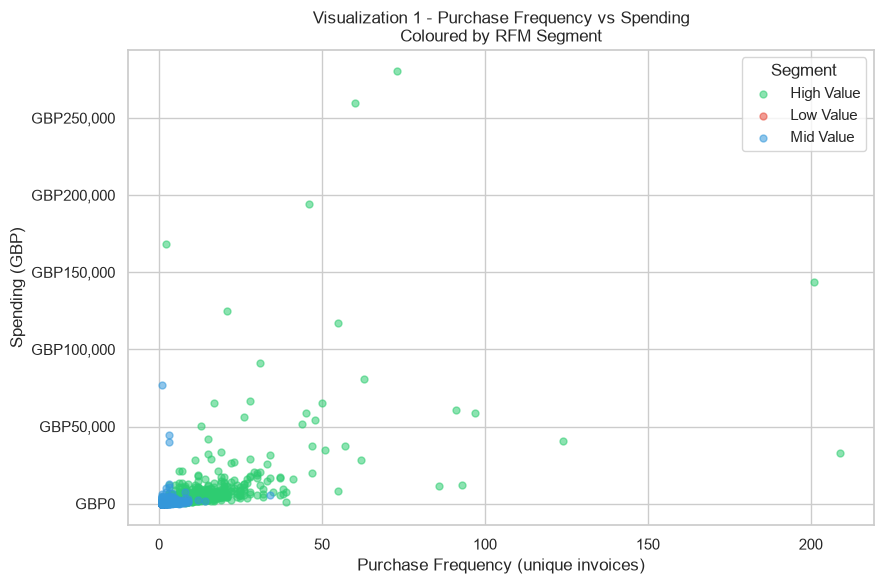

Saved: viz1_freq_vs_spending.png


In [24]:
fig, ax = plt.subplots(figsize=(9, 6))
for seg, grp in customers.groupby('Segment'):
    ax.scatter(grp['Purchase_Frequency'], grp['Spending'],
               label=seg, alpha=0.55, s=25, color=COLORS[seg])
ax.set_xlabel('Purchase Frequency (unique invoices)')
ax.set_ylabel('Spending (GBP)')
ax.set_title('Visualization 1 - Purchase Frequency vs Spending\nColoured by RFM Segment')
ax.legend(title='Segment')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: 'GBP{:,.0f}'.format(x)))
plt.tight_layout()
plt.savefig('viz1_freq_vs_spending.png', dpi=150)
plt.show()
print("Saved: viz1_freq_vs_spending.png")

### Visualization 2 - Recency vs Spending

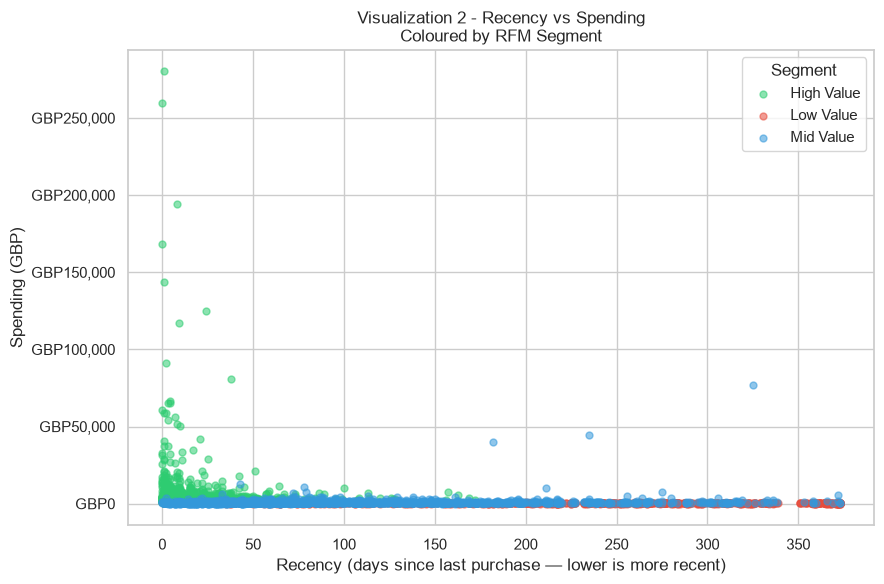

Saved: viz2_recency_vs_spending.png


In [25]:
fig, ax = plt.subplots(figsize=(9, 6))
for seg, grp in customers.groupby('Segment'):
    ax.scatter(grp['Recency'], grp['Spending'],
               label=seg, alpha=0.55, s=25, color=COLORS[seg])
ax.set_xlabel('Recency (days since last purchase — lower is more recent)')
ax.set_ylabel('Spending (GBP)')
ax.set_title('Visualization 2 - Recency vs Spending\nColoured by RFM Segment')
ax.legend(title='Segment')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: 'GBP{:,.0f}'.format(x)))
plt.tight_layout()
plt.savefig('viz2_recency_vs_spending.png', dpi=150)
plt.show()
print("Saved: viz2_recency_vs_spending.png")

### Visualization 3 - Customer Count by RFM Segment

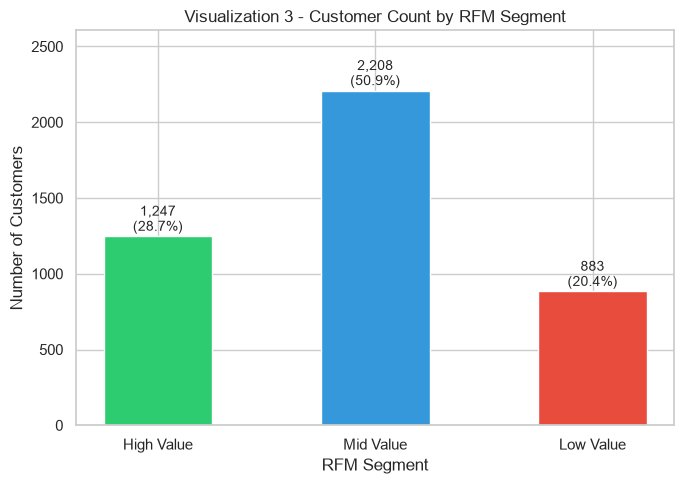

Saved: viz3_rfm_segments.png


In [26]:
seg_counts = customers['Segment'].value_counts().reindex(
    ['High Value', 'Mid Value', 'Low Value'])

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(seg_counts.index, seg_counts.values,
              color=[COLORS[s] for s in seg_counts.index],
              edgecolor='white', width=0.5)
for bar, val in zip(bars, seg_counts.values):
    pct = val / len(customers) * 100
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
            '{:,}\n({:.1f}%)'.format(val, pct),
            ha='center', va='bottom', fontsize=10)
ax.set_xlabel('RFM Segment')
ax.set_ylabel('Number of Customers')
ax.set_title('Visualization 3 - Customer Count by RFM Segment')
ax.set_ylim(0, seg_counts.max() * 1.18)
plt.tight_layout()
plt.savefig('viz3_rfm_segments.png', dpi=150)
plt.show()
print("Saved: viz3_rfm_segments.png")

### Visualization 4 - KNN Behavioural Anomaly Score Distribution

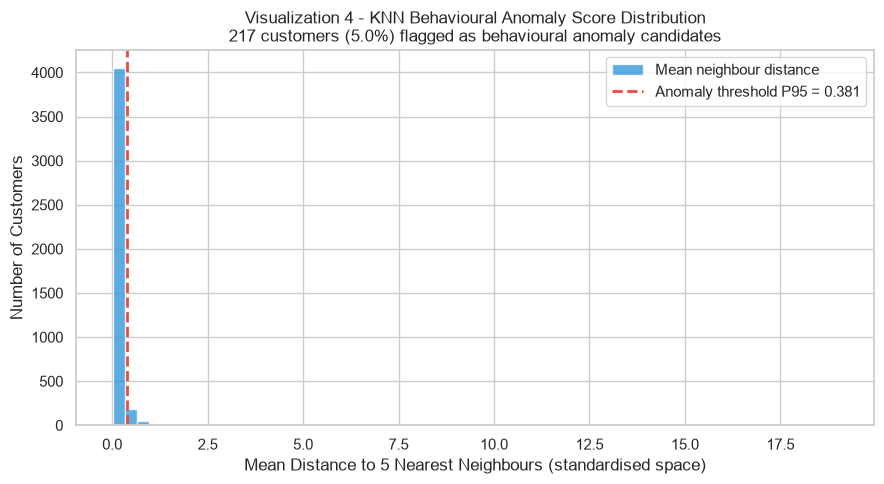

Saved: viz4_knn_anomaly.png


In [27]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(customers['KNN_Mean_Dist'], bins=60, color='#3498db',
        edgecolor='white', alpha=0.8, label='Mean neighbour distance')
ax.axvline(anomaly_threshold, color='#e74c3c', linewidth=2, linestyle='--',
           label='Anomaly threshold P95 = {:.3f}'.format(anomaly_threshold))
ax.set_xlabel('Mean Distance to {} Nearest Neighbours (standardised space)'.format(selected_k))
ax.set_ylabel('Number of Customers')
ax.set_title('Visualization 4 - KNN Behavioural Anomaly Score Distribution\n'
             '{} customers ({:.1f}%) flagged as behavioural anomaly candidates'.format(
             n_anomalies, pct_anomalies))
ax.legend()
plt.tight_layout()
plt.savefig('viz4_knn_anomaly.png', dpi=150)
plt.show()
print("Saved: viz4_knn_anomaly.png")

## 17. Key Insights (5-7, data-driven)

In [28]:
total_customers    = len(customers)
hv_count           = (customers['Segment'] == 'High Value').sum()
lv_count           = (customers['Segment'] == 'Low Value').sum()
hv_pct             = hv_count / total_customers * 100
lv_pct             = lv_count / total_customers * 100
hv_mean_spend      = customers[customers['Segment']=='High Value']['Spending'].mean()
lv_mean_spend      = customers[customers['Segment']=='Low Value']['Spending'].mean()
hv_mean_freq       = customers[customers['Segment']=='High Value']['Purchase_Frequency'].mean()
lv_mean_freq       = customers[customers['Segment']=='Low Value']['Purchase_Frequency'].mean()
hv_mean_recency    = customers[customers['Segment']=='High Value']['Recency'].mean()
lv_mean_recency    = customers[customers['Segment']=='Low Value']['Recency'].mean()
median_recency     = customers['Recency'].median()
freq_low_count     = len(freq_low)
heavy_infreq_count = len(heavy_infreq)
spend_ratio        = hv_mean_spend / lv_mean_spend

print("=" * 68)
print("KEY INSIGHTS")
print("=" * 68)
print()
print("Insight 1 - Customer base and segmentation")
print("  After cleaning, {:,} unique customers remain across 3 RFM segments.".format(
    total_customers))
print("  High Value: {:,} ({:.1f}%)  |  Mid Value: {:,} ({:.1f}%)  |  Low Value: {:,} ({:.1f}%)".format(
    hv_count, hv_pct,
    (customers['Segment']=='Mid Value').sum(),
    (customers['Segment']=='Mid Value').sum()/total_customers*100,
    lv_count, lv_pct))
print()
print("Insight 2 - Revenue concentration in High-Value segment")
print("  High-Value mean spend: GBP{:,.2f}".format(hv_mean_spend))
print("  Low-Value  mean spend: GBP{:,.2f}".format(lv_mean_spend))
print("  High-Value customers spend {:.1f}x more than Low-Value customers.".format(spend_ratio))
print("  This indicates strong revenue concentration in a minority of customers.")
print()
print("Insight 3 - Purchase frequency separates segments clearly")
print("  High-Value avg frequency : {:.1f} invoices".format(hv_mean_freq))
print("  Low-Value  avg frequency : {:.1f} invoices".format(lv_mean_freq))
print("  High-Value customers buy {:.1f}x more often.".format(hv_mean_freq/lv_mean_freq))
print()
print("Insight 4 - Recency distinguishes active from dormant customers")
print("  High-Value avg recency: {:.0f} days (very recent)".format(hv_mean_recency))
print("  Low-Value  avg recency: {:.0f} days (dormant)".format(lv_mean_recency))
print("  Median recency across all customers: {:.0f} days.".format(median_recency))
print()
print("Insight 5 - Frequent but low-spending customers exist")
print("  {:,} customers ({:.1f}%) buy more than the median ({:.0f} invoices)".format(
    freq_low_count, freq_low_count/total_customers*100, freq_median))
print("  but spend less than the median (GBP{:.2f}).".format(spending_median))
print("  These customers are engaged but generate below-average revenue.")
print()
print("Insight 6 - Heavy-spending infrequent customers represent re-engagement opportunity")
print("  {:,} customers ({:.1f}%) spend above the median (GBP{:.2f})".format(
    heavy_infreq_count, heavy_infreq_count/total_customers*100, spending_median))
print("  but purchase fewer than the median ({:.0f} invoices).".format(freq_median))
print("  These high-value occasional buyers are worth targeted re-engagement.")
print()
print("Insight 7 - KNN identifies a stable set of behavioural anomaly candidates")
print("  {:,} customers ({:.2f}%) exceed the P95 KNN distance threshold of {:.4f}.".format(
    n_anomalies, pct_anomalies, anomaly_threshold))
print("  The flagged set is identical across k=3,5,7,10, confirming these are")
print("  genuine extreme outliers in the behavioural feature space.")

KEY INSIGHTS

Insight 1 - Customer base and segmentation
  After cleaning, 4,338 unique customers remain across 3 RFM segments.
  High Value: 1,247 (28.7%)  |  Mid Value: 2,208 (50.9%)  |  Low Value: 883 (20.4%)

Insight 2 - Revenue concentration in High-Value segment
  High-Value mean spend: GBP5,452.72
  Low-Value  mean spend: GBP228.66
  High-Value customers spend 23.8x more than Low-Value customers.
  This indicates strong revenue concentration in a minority of customers.

Insight 3 - Purchase frequency separates segments clearly
  High-Value avg frequency : 10.0 invoices
  Low-Value  avg frequency : 1.0 invoices
  High-Value customers buy 9.6x more often.

Insight 4 - Recency distinguishes active from dormant customers
  High-Value avg recency: 19 days (very recent)
  Low-Value  avg recency: 224 days (dormant)
  Median recency across all customers: 50 days.

Insight 5 - Frequent but low-spending customers exist
  285 customers (6.6%) buy more than the median (2 invoices)
  but spe

## 18. Marketing Action Plan

In [29]:
rows = [
    ["High Value",
     "High RFM score; avg {:.0f} invoices; avg GBP{:,.0f} spend; avg {:.0f} days recency".format(
         hv_mean_freq, hv_mean_spend, hv_mean_recency),
     "Core revenue drivers; loyal and recently active customers",
     "VIP loyalty programme; early product access; personalised retention offers"],
    ["Low Value",
     "Low RFM score; avg {:.0f} invoices; avg GBP{:,.0f} spend; avg {:.0f} days recency".format(
         lv_mean_freq, lv_mean_spend, lv_mean_recency),
     "Churned or disengaged customers; high recency indicates dormancy",
     "Win-back email with time-limited offer; deprioritise if no response"],
    ["Mid Value",
     "Moderate RFM score; average frequency and spend",
     "Growth opportunity; potential to move into High Value tier",
     "Upsell and cross-sell campaigns; bundle offers to increase basket size"],
    ["Frequent + Low-Spending",
     "Freq > median ({:.0f}); Spend < median (GBP{:.2f}); {:,} customers".format(
         freq_median, spending_median, freq_low_count),
     "Engaged but low-basket customers; buying mainly low-price items",
     "Minimum-spend incentives; recommend higher-value complementary products"],
    ["Heavy-Spending + Infrequent",
     "Spend > median (GBP{:.2f}); Freq < median ({:.0f}); {:,} customers".format(
         spending_median, freq_median, heavy_infreq_count),
     "High-value occasional buyers; possibly seasonal or project-based",
     "Seasonal re-engagement campaigns; subscription or bulk-order incentives"],
    ["Behavioural Anomaly Candidates",
     "KNN mean dist > {:.4f} (P95); {:,} customers ({:.1f}%)".format(
         anomaly_threshold, n_anomalies, pct_anomalies),
     "Unusual purchase patterns vs behavioural peers; not necessarily invalid",
     "Manual review; may represent niche segments, bulk traders, or data issues"],
]

cols = ["Segment / Behaviour", "Observed Characteristics",
        "Possible Business Interpretation", "Suggested Marketing Action"]
action_df = pd.DataFrame(rows, columns=cols)
pd.set_option('display.max_colwidth', 65)
print(action_df.to_string(index=False))

           Segment / Behaviour                                                 Observed Characteristics                                        Possible Business Interpretation                                                 Suggested Marketing Action
                    High Value High RFM score; avg 10 invoices; avg GBP5,453 spend; avg 19 days recency               Core revenue drivers; loyal and recently active customers VIP loyalty programme; early product access; personalised retention offers
                     Low Value    Low RFM score; avg 1 invoices; avg GBP229 spend; avg 224 days recency        Churned or disengaged customers; high recency indicates dormancy        Win-back email with time-limited offer; deprioritise if no response
                     Mid Value                          Moderate RFM score; average frequency and spend              Growth opportunity; potential to move into High Value tier     Upsell and cross-sell campaigns; bundle offers to increase basket s

## 19. Limitations

1. **Discount_Usage excluded** — The UCI Online Retail dataset contains no
   discount rate, coupon code, original price, or markdown field.
   Discount_Usage cannot be calculated without fabricating data and is
   therefore excluded from this analysis. The assignment specification lists
   this as a provided feature; in this dataset it does not exist.

2. **Missing CustomerID (24.9% of raw rows)** — 135,037 rows had no
   CustomerID and were removed. These transactions cannot be attributed
   to any customer and are excluded from all customer-level analysis.

3. **No ground-truth labels for KNN** — KNN is used in unsupervised mode
   (NearestNeighbors). Flagged customers are anomaly candidates, not
   confirmed anomalies. Classification metrics are not applicable.

4. **Single-country dominance** — 91.4% of transactions are from the
   United Kingdom. Insights may not generalise to international customers.

5. **One-year snapshot** — Data covers 2010-12-01 to 2011-12-09 only.
   Seasonal patterns and long-term trends cannot be assessed.

6. **Spending includes bulk orders** — Extreme bulk purchases are retained
   as legitimate. They inflate Spending skewness (19.33) and affect the
   mean more than the median for a small number of customers.

## 20. Conclusion

This project applied RFM analysis and unsupervised KNN behavioural similarity
to the UCI Online Retail dataset to answer: **Who are our customers?**

**Summary of deliverables:**

| Requirement | Status |
|---|---|
| Clean and validate dataset | Done — 4 cleaning steps, 4,338 customers retained |
| Descriptive statistics | Done — count, mean, median, std, min, Q1, Q3, max + skewness |
| 4 visualizations | Done — Viz 1-4 produced and saved |
| RFM metrics | Done — R, F, M scored on quintile 1-5 scale |
| Meaningful customer groups | Done — High/Mid/Low Value via RFM_Score quartiles |
| High-value vs low-value comparison | Done — Section 10 |
| Frequent + low-spending customers | Done — Section 11 |
| Heavy-spending + infrequent customers | Done — Section 12 |
| KNN model (NearestNeighbors) | Done — k=5, StandardScaler, 4 features |
| Flag behavioural anomaly candidates | Done — 217 customers (5%) at P95 threshold |
| KNN evaluation | Done — distance distribution, k-sensitivity table |
| 5-7 key insights | Done — 7 insights, all numbers from dataset |
| Marketing action plan | Done — 6-row action table |
| Limitations | Done — Section 19 |

**Key finding:** A small group of High-Value customers (28.7%) drives
disproportionate revenue, spending 23.8x more than Low-Value customers.
The KNN anomaly detection identified 217 customers with unusual behavioural
patterns that warrant individual review.